In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-02-08 17:19:10.377900: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-02-08 17:19:10.484216: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-08 17:19:10.484272: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-08 17:19:10.486596: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-08 17:19:10.502573: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-02-08 17:19:10.503912: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [15]:
N = 93
K = 10

V_width = 1
V_E_buffer_array = np.arange(20).astype(int)
E_width = 1

stim = 'opticflow'
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', stim)

In [16]:
sweep_dims = (len(V_E_buffer_array),)
bank_data = np.zeros(sweep_dims, dtype=object)
basis_neurons = np.zeros(sweep_dims, dtype=object)

for i, V_E_buffer in enumerate(V_E_buffer_array):
    load_path = os.path.join(bank_directory, f'({V_width},{V_E_buffer},{E_width}) K={K}.dat')
    with open(load_path, 'rb') as f:
        data_dict = pickle.load(f)
    basis_neurons[i] = data_dict["basis_vectors"]
    bank_data[i] = data_dict

mov_name = data_dict["mov_name"]

In [11]:
ref = basis_neurons[0]
for i in range(len(V_E_buffer_array)):
    for k in range(K):
        cur_leading = basis_neurons[i][:,k]
        cur_sign = np.sign(ref[:,k] @ cur_leading)
        basis_neurons[i][:,k] *= cur_sign

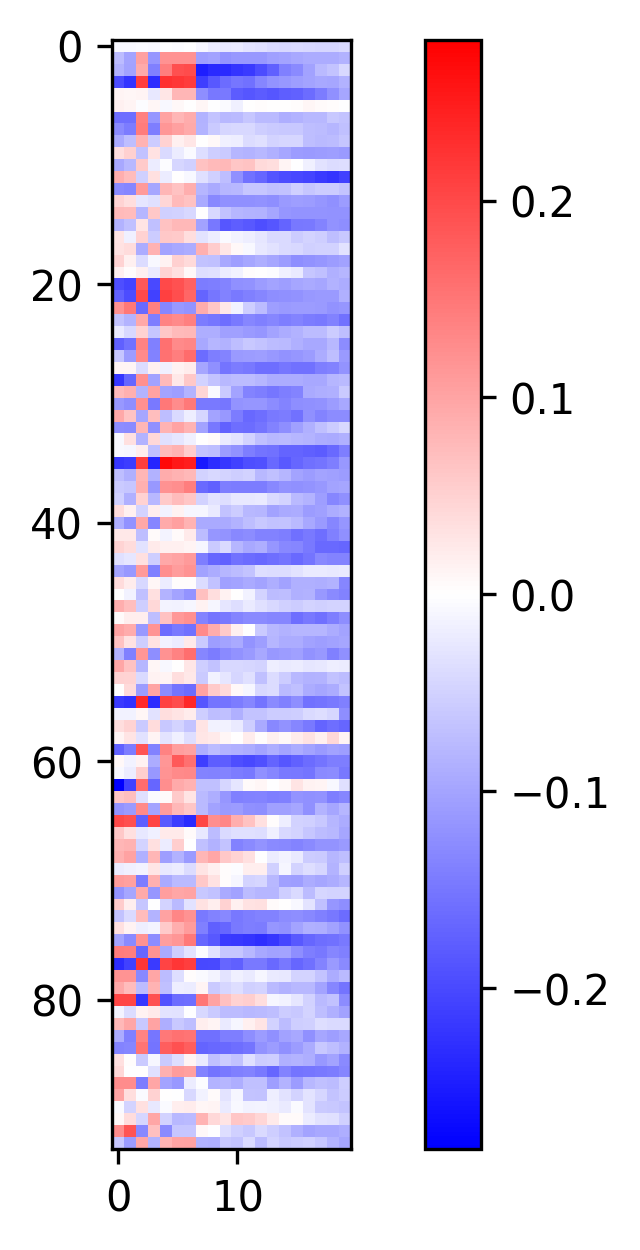

In [34]:
mode_index = 0
viewing_dims = (V_width, N)
modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]

plt.figure(dpi=300)
stacked = np.concatenate(modes, axis=1)
mx = np.amax(np.abs(stacked))
plt.imshow(stacked[:,::-1], cmap='bwr', vmin=-mx, vmax=mx)
plt.colorbar()

In [17]:
stim_names = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
stim_inds = {k:i for i,k in enumerate(stim_names)}

data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=stim_inds[stim])

In [37]:
T = len(V_E_buffer_array)
C = [als.autocorrelation(D.X, t) for t in range(1,T+1)]
C = np.stack(C, axis=1)

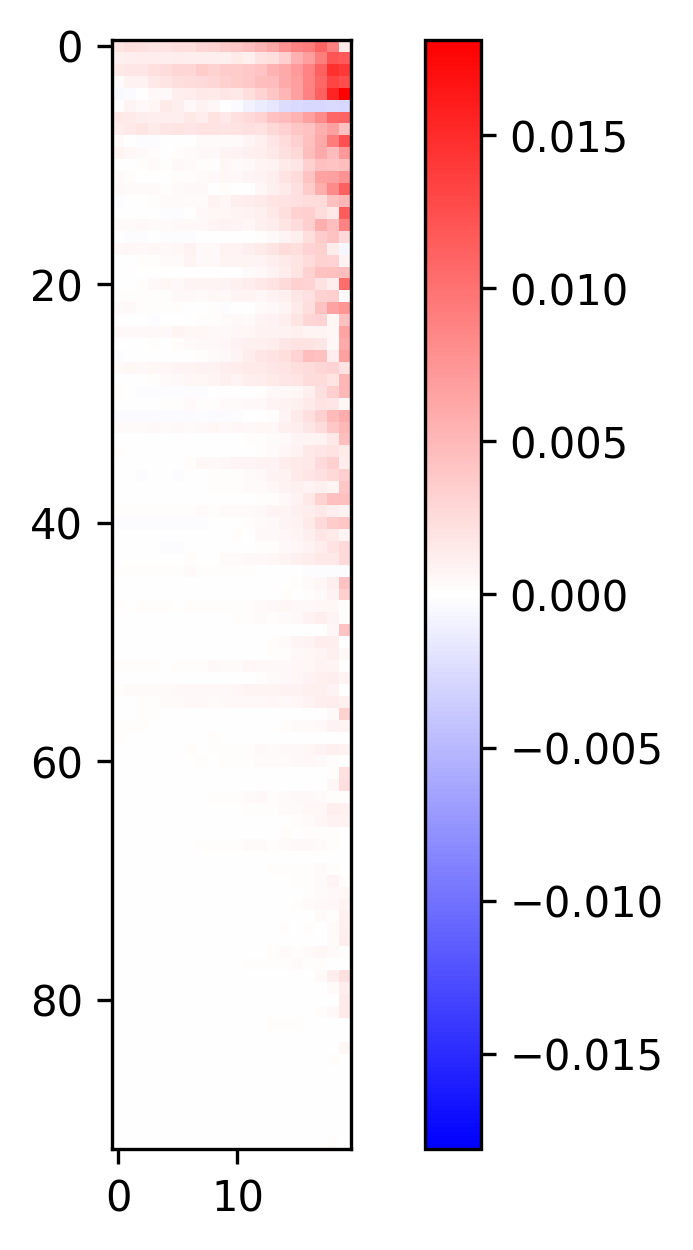

In [40]:
plt.figure(dpi=300)
# stacked = np.concatenate(modes, axis=1)
mx = np.amax(np.abs(C))
plt.imshow(C[:,::-1], cmap='bwr', vmin=-mx, vmax=mx)
plt.colorbar()

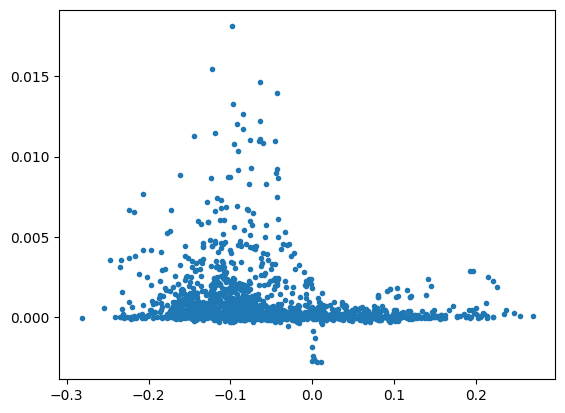

In [41]:
plt.plot(stacked.flatten(), C.flatten(),'.')

In [50]:
# C0 = als.autocorrelation(D.X, 0)
C0 = np.sqrt(np.sum(C**2, axis=1))
Cnormed = C / C0[:,None]

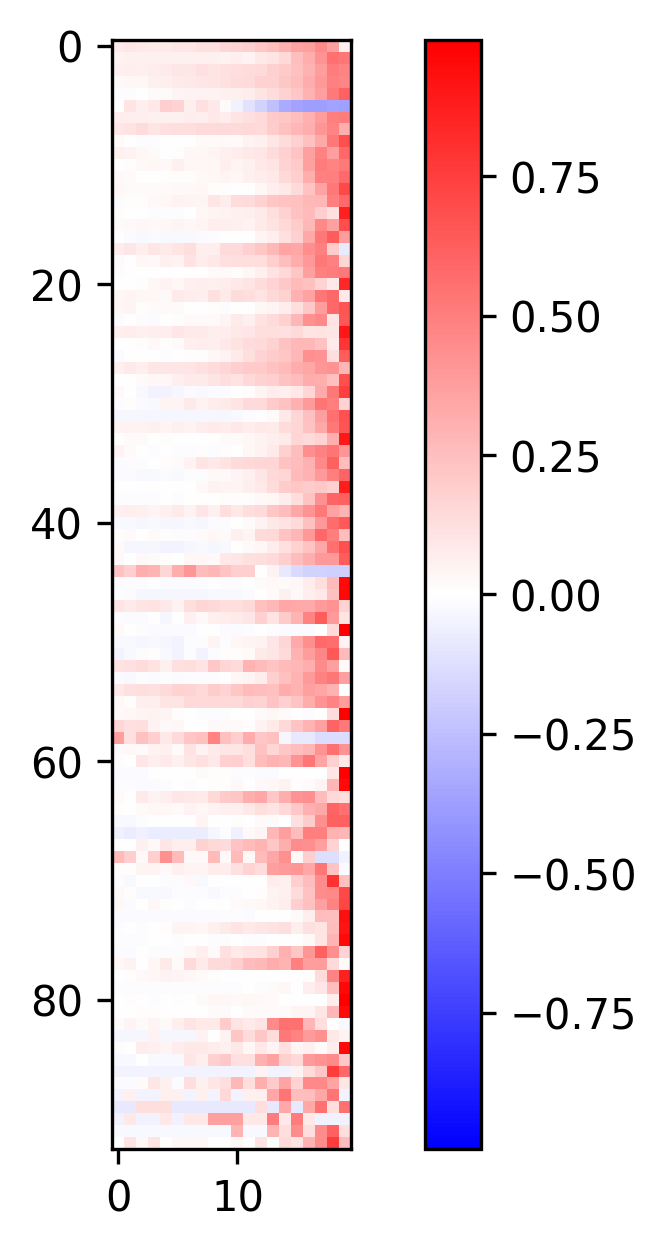

In [51]:
plt.figure(dpi=300)
# stacked = np.concatenate(modes, axis=1)
mx = np.amax(np.abs(Cnormed))
plt.imshow(Cnormed[:,::-1], cmap='bwr', vmin=-mx, vmax=mx)
plt.colorbar()

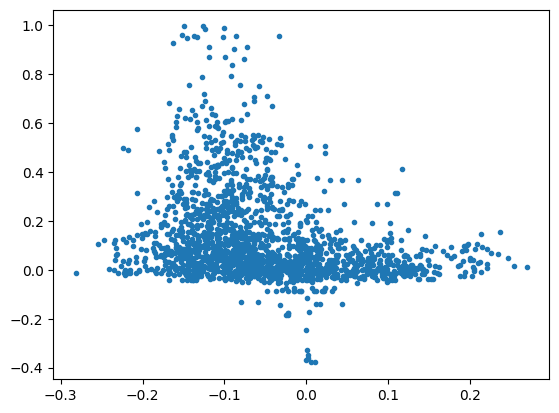

In [52]:
plt.plot(stacked.flatten(), Cnormed.flatten(),'.')